In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Mathlete Probability

## Quiz_4.1

- Let X be the number of times head is obtained when a coin is tossed 3 times

### python solution 

In [5]:
head_tail_3 =["TTT","THH","TTH","THT","HHH","HTT","HHT","HTH"]
len_n       =len(head_tail_3)
keys        =["H","T"]
counter=[]
head_cn=[]
tail_cn=[]

for i in range(len_n):
        counter.append(Counter(head_tail_3[i]))
        head_cn.append(counter[i][keys[0]])
        tail_cn.append(counter[i][keys[1]])
    
df=pd.DataFrame( { "head_tail_3":head_tail_3,
                   "Count":counter,
                   "T_count":tail_cn,
                   "H_Count":head_cn},
                    index=map(lambda x : "case_{}".format(ord(chr(x))) ,np.arange(1,1+len_n))  )
df

,head_tail_3,Count,T_count,H_Count
case_1,TTT,{'T': 3},3,0
case_2,THH,"{'T': 1, 'H': 2}",1,2
case_3,TTH,"{'T': 2, 'H': 1}",2,1
case_4,THT,"{'T': 2, 'H': 1}",2,1
case_5,HHH,{'H': 3},0,3
case_6,HTT,"{'H': 1, 'T': 2}",2,1
case_7,HHT,"{'H': 2, 'T': 1}",1,2
case_8,HTH,"{'H': 2, 'T': 1}",1,2


In [4]:
counter

[Counter({'T': 3}),
 Counter({'H': 2, 'T': 1}),
 Counter({'T': 2, 'H': 1}),
 Counter({'T': 2, 'H': 1}),
 Counter({'H': 3}),
 Counter({'T': 2, 'H': 1}),
 Counter({'H': 2, 'T': 1}),
 Counter({'H': 2, 'T': 1})]

In [6]:
counter[3]['H']

1

In [7]:
dict_sorted = sorted( Counter( df[ 'H_Count' ] ).items(), key= lambda item : item[0] )
for key ,val in dict_sorted:
    df["{}_Head".format(key)]=("$\\frac{}{}$".format(val, len_n))
df_head=df.copy()

In [8]:
df_head

,head_tail_3,Count,T_count,H_Count,0_Head,1_Head,2_Head,3_Head
case_1,TTT,{'T': 3},3,0,$\frac18$,$\frac38$,$\frac38$,$\frac18$
case_2,THH,"{'T': 1, 'H': 2}",1,2,$\frac18$,$\frac38$,$\frac38$,$\frac18$
case_3,TTH,"{'T': 2, 'H': 1}",2,1,$\frac18$,$\frac38$,$\frac38$,$\frac18$
case_4,THT,"{'T': 2, 'H': 1}",2,1,$\frac18$,$\frac38$,$\frac38$,$\frac18$
case_5,HHH,{'H': 3},0,3,$\frac18$,$\frac38$,$\frac38$,$\frac18$
case_6,HTT,"{'H': 1, 'T': 2}",2,1,$\frac18$,$\frac38$,$\frac38$,$\frac18$
case_7,HHT,"{'H': 2, 'T': 1}",1,2,$\frac18$,$\frac38$,$\frac38$,$\frac18$
case_8,HTH,"{'H': 2, 'T': 1}",1,2,$\frac18$,$\frac38$,$\frac38$,$\frac18$


In [9]:
df_head["H_Count"].sum()

np.int64(12)

In [10]:
len(df_head["H_Count"])

8

In [11]:
df_head["H_Count"].sum()/len(df_head["H_Count"])

np.float64(1.5)

$\frac{1(0)}{8} + \frac{3(1,1,1)}{8} + \frac{3(2,2,2)}{8}$

$\frac{0}{8} + \frac{3}{8} + \frac{6}{8} + \frac{3}{8}= \frac{12}{8}$

$\frac{1(0)}{8} + \frac{3(1,1,1)}{8} + \frac{3(2,2,2)}{8} + \frac{1(3)}{8}= \frac{\cancel{12}^{\quad 3}}{\cancel{8}^{\quad 2}}$

In [322]:
prob = df_head.loc["case_1","0_Head":].to_frame().T
prob['Prob_Sum']="$\\frac{8}{8}=1$"
prob.index=["#_H_8Cases"]
prob['Mean']="E(X)=$\\mu =\\Sigma x \\cdot p(X)$"
prob['Variance']="Var(x)=$\\Sigma[x -\\mu]^2 \\cdot p(X)$"
prob

,0_Head,1_Head,2_Head,3_Head,Prob_Sum,Mean,Variance
#_H_8Cases,$\frac18$,$\frac38$,$\frac38$,$\frac18$,$\frac{8}{8}=1$,E(X)=$\mu =\Sigma x \cdot p(X)$,Var(x)=$\Sigma[x -\mu]^2 \cdot p(X)$


## Quiz_4.2

- A fair spinner has sides numbered 1, 2, 2.
- Another fair spinner has sides numbered −2, 0, 1.
- Each spinner is spun.The number on the side on which a spinner comes to rest is noted.
- The random variable X is the sum of the numbers for the two spinners.
  - (a) Draw up the probability distribution table for X.
  - find E(X) and Var(X)

#### python solution

In [13]:
spin1=[1,2,2]
spin2=[-2,0,1]

mat_spin=np.zeros((3,3),dtype="object")
for i in range(3):
    for j in range(3):
        mat_spin[i,j]=spin1[i]+spin2[j]

mat_spin

array([[-1, 1, 2],
       [0, 2, 3],
       [0, 2, 3]], dtype=object)

In [14]:
df_spin=pd.DataFrame(   data=mat_spin,
                        index=map(lambda x: "Spin1_{}".format(chr(x)), np.arange(97,97+3)),
                        columns = map(lambda y : "Spin2_{}".format(chr(y)),np.arange(65,65+3)))
df_spin

,Spin2_A,Spin2_B,Spin2_C
Spin1_a,-1,1,2
Spin1_b,0,2,3
Spin1_c,0,2,3


In [15]:
dic_count=sorted(Counter(mat_spin.flatten()).items(), key=lambda item : item[0])
sum_val=0
for key , val in dic_count:
    sum_val=sum_val+val
for key , val in dic_count:
    df_spin["{}_Cnt".format(key)]="$\\frac{}{}$".format(val,sum_val)
df_spin_c=df_spin.copy()
df_spin_c

,Spin2_A,Spin2_B,Spin2_C,-1_Cnt,0_Cnt,1_Cnt,2_Cnt,3_Cnt
Spin1_a,-1,1,2,$\frac19$,$\frac29$,$\frac19$,$\frac39$,$\frac29$
Spin1_b,0,2,3,$\frac19$,$\frac29$,$\frac19$,$\frac39$,$\frac29$
Spin1_c,0,2,3,$\frac19$,$\frac29$,$\frac19$,$\frac39$,$\frac29$


In [16]:
type(Counter(mat_spin.flatten()))

collections.Counter

In [17]:
type(dic_count)

list

In [19]:
xxxx = Counter(mat_spin.flatten())
for key , val in xxxx.items():
    print("key unpacked  :--------{}".format(key))
    print("val unpacked  :--------{}".format(val))
    print("--------------------------------------")

key unpacked  :---------1
val unpacked  :--------1
--------------------------------------
key unpacked  :--------1
val unpacked  :--------1
--------------------------------------
key unpacked  :--------2
val unpacked  :--------3
--------------------------------------
key unpacked  :--------0
val unpacked  :--------2
--------------------------------------
key unpacked  :--------3
val unpacked  :--------2
--------------------------------------


In [20]:
lst =[("sd","dd"),("t","e"),("we","yy")]

for x , y in lst:
    print("x unpacked  :--------{}".format(x))
    print("y unpacked  :--------{}".format(y))
    print("--------------------------------------")

x unpacked  :--------sd
y unpacked  :--------dd
--------------------------------------
x unpacked  :--------t
y unpacked  :--------e
--------------------------------------
x unpacked  :--------we
y unpacked  :--------yy
--------------------------------------


In [21]:
df_spin_c.style.background_gradient(subset=['Spin2_A',"Spin2_B","Spin2_C"],cmap="twilight").\
                set_table_styles([ {"selector":"th","props":"border:double white 3px"},
                                   {"selector":"td","props":"border:solid white 3px"}  ])

,Spin2_A,Spin2_B,Spin2_C,-1_Cnt,0_Cnt,1_Cnt,2_Cnt,3_Cnt
Spin1_a,-1,1,2,$\frac19$,$\frac29$,$\frac19$,$\frac39$,$\frac29$
Spin1_b,0,2,3,$\frac19$,$\frac29$,$\frac19$,$\frac39$,$\frac29$
Spin1_c,0,2,3,$\frac19$,$\frac29$,$\frac19$,$\frac39$,$\frac29$


In [22]:
x   = [-1,0,1,2,3]
f_x = [1/9,2/9,1/9,3/9,2/9]

E_X =0 
for i in range(5):
    E_X=E_X+ x[i]*f_x[i]
E_X

1.3333333333333333

In [23]:
4/3

1.3333333333333333

In [24]:
mat_spin

array([[-1, 1, 2],
       [0, 2, 3],
       [0, 2, 3]], dtype=object)

In [25]:
mat_spin.flatten().mean()

np.float64(1.3333333333333333)

In [26]:
mat_spin

array([[-1, 1, 2],
       [0, 2, 3],
       [0, 2, 3]], dtype=object)

In [27]:
mat_spin.flatten()

array([-1, 1, 2, 0, 2, 3, 0, 2, 3], dtype=object)

In [28]:
r_varbl_uniq = np.unique(mat_spin.flatten())

In [29]:
val_l=[]
for key , val in sorted(Counter(mat_spin.flatten()).items(), key =lambda item: item[0]):
    val_l.append(val)

val_l
r_varble_val=np.array(val_l)

In [30]:
sorted(Counter(mat_spin.flatten()).items(), key =lambda item: item[0])

[(-1, 1), (0, 2), (1, 1), (2, 3), (3, 2)]

In [31]:
(r_varbl_uniq*(r_varble_val/9)).sum()

1.3333333333333333

In [32]:
df_mean = pd.DataFrame({"uniq_values": r_varbl_uniq,
                        "Counts":r_varble_val,
                        "val_prob":np.around(r_varble_val/9,2),
                         "Mean":np.around((r_varbl_uniq*(r_varble_val/9)).sum(),2)},
                        index =map(lambda x:"Case_{}".format(x),np.arange(1,6)))

df_mean.loc["Sum",["Counts","val_prob"]]=np.around(df_mean[["Counts",'val_prob']].sum(axis=0),1)
df_mean.loc["Sum",["uniq_values","Mean"]]=df_mean.loc["Sum",["uniq_values","Mean"]].fillna(0.00000001)
df_mean.style.map(lambda x: "color:black" if x==0.00000001 else "color:white").\
              background_gradient(subset="Counts",cmap="turbo").\
              format("{:.2f}",subset=["val_prob","Mean"])

,uniq_values,Counts,val_prob,Mean
Case_1,-1,1,0.11,1.33
Case_2,0,2,0.22,1.33
Case_3,1,1,0.11,1.33
Case_4,2,3,0.33,1.33
Case_5,3,2,0.22,1.33
Sum,0.000000,9,1.00,0.00


#### Random variable Notes

<div style="background-color:beige;color:indigo">
<mark><u><b>Random Variable X</b></u></mark> is a collection of values for each outcome of a procedure 
 <br> &emsp;that's determined by chance X=[  $x_i$ .....]
<ol style="border:double black 6px;color:black">
    <li >Discrete Random Variable - that's countable or finite |die side| |prob is represented by frequency table count of each value -then divided by total number of possible outcomes| 
        <br> &emsp; sum of all the probabilities =1 
        <br> &emsp; examples : coin flipped 3 times - number of heads 
        <br> &emsp; examples : two dice rolled together - sum table  
        <br> &emsp; Probability mass function -table  |PMF gives the probability distriution of x - probability law adds up to 1|
    </li>
    <li >continuous Random Variable - that's uncountable or infinite | bins usually measurements height weight | |prob is represented by area under the curve|<br> &emsp; area under the curve is 1 (area is probability |becuase only interval can be used for continuous variable| )
        <br> &emsp; eamxples normal | t f chi2 distribution 
        <br> &emsp; instead of using frequency distribution table - to calculate probability - use cdf ppf sf functions to calculate area (probability) 
        <br> &emsp; Probabilities for continuous random variables come from areas under the curve over intervals, not single points.
        <br> &emsp; &emsp;The area under the curve = probability that the variable takes a value in that interval.
        <br> &emsp; &emsp;The probability of one exact value is zero.</li>
</ol>
probability distribution<br>
 A table that gives the probability for each value of a random variable
    <br>Example Die Roll</div><div style="font-size:20px"> 
<table style="text-align:left;border:double white 3px"><th>X</th><th>P(X)</th><th>Comment</th><tr><td style="border:dotted yellow 2px">1</td><td style="border:dotted yellow 2px">$\frac{1}{6}$</td><td style="border:dotted yellow 2px">Side_One</td></tr><tr><td>2</td><td>$\frac{1}{6}$</td><td>Side_Two</td></tr><tr><td>3</td><td>$\frac{1}{6}$</td><td>Side_Three</td></tr><tr><td>4</td><td>$\frac{1}{6}$</td><td>Side_Four</td></tr><tr><td>5</td><td>$\frac{1}{6}$</td><td>Side_Five</td></tr><tr><td>6</td><td>$\frac{1}{6}$</td><td>Side_Six</td></tr></table>
 </div>
<div style="font-size:20px;background-color:indigo;color:cyan">
 $\mu =\frac{\Sigma(x \cdot f)}{N}$  &emsp;  $\mu =\Sigma[ \frac{x \cdot f}{N} ]$ &emsp;$\mu =\Sigma[ x \cdot \frac{ f}{N} ] $ &emsp; 
$p(x)=\frac{f}{N}$  <br>    <span style="font-size:20px">$[2,2,2,1,1,1,0,3]$ &rarr;[2*3 1*3 0*1 3*1] $f$=frequency | count $\frac{2 \cdot 3}{8} +\frac{0 \cdot 1}{8}+\frac{1 \cdot 3}{8} +\frac{1 \cdot 3}{8}+\frac{3\cdot1}{8}= \frac{2\cdot3+0\cdot1+1\cdot3+3\cdot1}{8}=\frac{3}{2}$ </span>
<br> $\textcolor{yellow}{x}\cdot \textcolor{red}{f}= \underbrace{\textcolor{yellow}{x+x+...}}_{\tiny \textcolor{red}{\text{number of x -count}}}$
<hr>
var(x)=$\sigma^2=\Sigma[\ x^2 \ \cdot \  P(x) \ ] - \mu^2 =\sigma^2=\Sigma[x-\mu]^2 \cdot P(x)$
</div>
Denominator is the same |arr.sum/len(arr) |
<hr>

In [33]:
die_roll_3=np.array([2,2,2,1,1,1,0,3])
int(die_roll_3.sum())

12

In [34]:
key=[]
val=[]
for x, y in Counter(die_roll_3).items():
    key.append(int(x))
    val.append(int(y))

sum_dic=0
sum_Lis=[]
for i in range(4):
   sum_dic=sum_dic+ key[i]*val[i]
   sum_Lis.append((key[i]*val[i]))
print("""number of heads         :{}  
it's count/frequency    :{}
x*f sum is              :{} 
                        [2*3+1*3+0*1+3*1]=12
-----------------------------------------------
                          |  |   |  |
                  [2+2+2]=6  |   |  |
                     [1+1+1]=3   |  |
                            [0]=0   |
                                [3]=3 
Sum is                  :{}
x times frequency = x1 + x2 +..
addition to multiplication
""".format(key,val,sum_Lis,sum_dic))

x_plt_list=key.copy()
y_plt_list=val.copy()

number of heads         :[2, 1, 0, 3]  
it's count/frequency    :[3, 3, 1, 1]
x*f sum is              :[6, 3, 0, 3] 
                        [2*3+1*3+0*1+3*1]=12
-----------------------------------------------
                          |  |   |  |
                  [2+2+2]=6  |   |  |
                     [1+1+1]=3   |  |
                            [0]=0   |
                                [3]=3 
Sum is                  :12
x times frequency = x1 + x2 +..
addition to multiplication



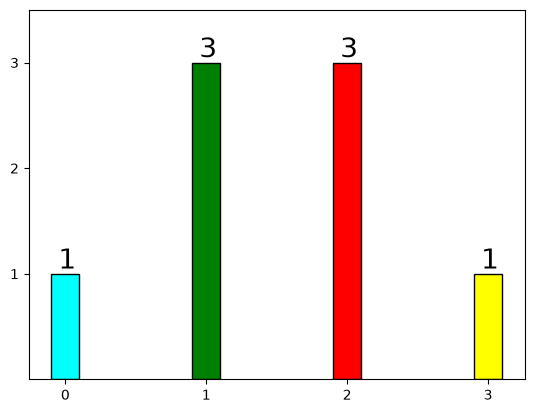

In [35]:
fig,ax=plt.subplots(1,1)
ax.bar(x_plt_list,y_plt_list,color=["red","green","cyan","yellow"],edgecolor="black",width=0.2)
ax.set_xticks([0,1,2,3])
ax.set_ylim(0,3.5)
ax.set_yticks([1,2,3])
for i in range(4):
    ax.annotate("{}".format(y_plt_list[i]),xy=(x_plt_list[i]-0.05,y_plt_list[i]+0.05),size=20)
plt.show()

## Quiz_4.3 TrevTutor

- A car tune-up is preventive maintenance that restores engine performance by replacing wear items like spark plugs and filters and inspecting key systems.
- .--------------------------------------------------------------------------------------
- 45% of tune-ups are done on four-cylinders, 40% on six-cyliners and 15% on eight-cylinders . Let X= Numerb of cyliners.
  - a what's the pmf of x
  - what's P(X>4)
  - what's P(X>6)

### python solution

#### a

In [73]:
X=[4,6,8]
Y=[.45,.4,.15]

df_tuneups =pd.DataFrame(data={"X":X,"P(X)":Y})
df_tuneups

,X,P(X)
0,4,0.45
1,6,0.40
2,8,0.15


#### b

In [142]:
df_tuneups_greater_than_4 =df_tuneups.copy()

def index_style1(x):
  return  np.where(x>0 ,"color:red;background-color:yellow;border:double blue 2px","")
df_tuneups_greater_than_4.style.map(lambda x: "olor:red;background-color:yellow;border:double white 2px" if x>4 else "color:white")\
                                 .apply_index(index_style1).format("{:.2f}",subset="P(X)").\
                                 set_table_styles([{"selector":"td.row1,td.row2","props":"color:red;background-color:yellow;border:double blue 2px"},
                                                                                    {"selector":"" ,"props":"border:double cyan"},])

,X,P(X)
0,4,0.45
1,6,0.40
2,8,0.15


In [68]:
tuneup_greater_than_4= df_tuneups[df_tuneups["X"]>4]['P(X)'].sum()

In [69]:
print("what's P(X>4) ans :{:.2f}%".format( tuneup_greater_than_4 * 100 ))

what's P(X>4) ans :55.00%


#### c

In [143]:
df_tuneups_greater_than_6 =df_tuneups.copy()

def index_style1(x):
  return  np.where(x>1 ,"color:red;background-color:yellow;border:double blue 2px","")
df_tuneups_greater_than_6.style.map(lambda x: "olor:red;background-color:yellow;border:double white 2px" if x>6 else "color:white")\
                                 .apply_index(index_style1).format("{:.2f}",subset="P(X)").\
                                 set_table_styles([{"selector":"td.row2","props":"color:red;background-color:yellow;border:double blue 2px"},
                                                                                    {"selector":"" ,"props":"border:double cyan"},])

,X,P(X)
0,4,0.45
1,6,0.40
2,8,0.15


In [91]:
tuneup_greater_than_6= df_tuneups.query("X>6")['P(X)'].sum()

In [92]:
print("what's P(X>6) ans :{:.2f}%".format( tuneup_greater_than_6 * 100 ))

what's P(X>6) ans :15.00%


## Quiz_4.3 TrevTutor

- Let p(y) = ky for y = 1,2,3,4,5
  - whats the value of k?
  - what's the probability that y < 4?
  - what's the probability that 1<y<5?

### python solution

In [98]:
import sympy as sympy 
k   = sympy.symbols("k")
eq  = sympy.Eq(1,1*k+2*k+3*k+4*k+5*k)
eq

Eq(1, 15*k)

In [103]:
ans_quiz43 = sympy.solve(eq,k)
ans_quiz43

[1/15]

In [132]:
y          = np.arange(1,6)
p_y        = y*ans_quiz43

df_quiz43  = pd.DataFrame(data ={"y":y,"p(y)":p_y},
                          index=map(lambda x : "Row_{}".format(x), np.arange(1,6)))

In [133]:
df_quiz43.style.background_gradient(cmap="turbo")

,y,p(y)
Row_1,1,1/15
Row_2,2,2/15
Row_3,3,1/5
Row_4,4,4/15
Row_5,5,1/3


In [141]:
df_quiz43.style.set_table_styles([{"selector":"td.row0,td.row1,td.row2","props":"color:red;background-color:yellow"},
                                                                    {"selector":"" ,"props":"border:double cyan"},
                                  {"selector":"th.row0,th.row1,th.row2","props":"color:red;background-color:yellow"}])

,y,p(y)
Row_1,1,1/15
Row_2,2,2/15
Row_3,3,1/5
Row_4,4,4/15
Row_5,5,1/3


In [135]:
df_quiz43.query("y<4")['p(y)'].sum()

2/5

In [136]:
df_quiz43.query("y<4")['p(y)'].sum().evalf()

0.400000000000000

In [140]:
df_quiz43.style.set_table_styles([{"selector":"th.row1,th.row2,th.row3", "props":"color:red;background-color:yellow"},
                                  {"selector":"" ,"props":"border:double cyan"},
                                  {"selector":"td.row1,td.row2,td.row3", "props":"color:red;background-color:yellow"}])

,y,p(y)
Row_1,1,1/15
Row_2,2,2/15
Row_3,3,1/5
Row_4,4,4/15
Row_5,5,1/3


In [138]:
df_quiz43.query("1<y<5")['p(y)'].sum()

3/5

In [139]:
df_quiz43.query("1<y<5")['p(y)'].sum().evalf()

0.600000000000000

## Quiz_4.4

Dice Roll 2 

### python solution 

#### df from matrix

In [181]:
die_q44    = np.arange(1,7)

matrix_q44 = np.random.randn(6,6)
for i in range(6):
    for j in range(6):
        matrix_q44[i,j]=die_q44[i]+die_q44[j]
df_q44= pd.DataFrame(data=matrix_q44,
                     index =map(lambda x: "D1_Side_{}".format(x),die_q44),
                     columns =map(lambda y : "D2S{}".format(y),die_q44))
df_q44=df_q44.map(lambda x: int(x))
df_q44

,D2S1,D2S2,D2S3,D2S4,D2S5,D2S6
D1_Side_1,2,3,4,5,6,7
D1_Side_2,3,4,5,6,7,8
D1_Side_3,4,5,6,7,8,9
D1_Side_4,5,6,7,8,9,10
D1_Side_5,6,7,8,9,10,11
D1_Side_6,7,8,9,10,11,12


#### PMF frequency table -probability distribution 

In [182]:
dictc=Counter(matrix_q44.flatten())
for key ,val in dictc.items():
    df_q44['$\\Sigma{}$'.format(int(key))]="{}/36".format(val)
df_q44

,D2S1,D2S2,D2S3,D2S4,D2S5,D2S6,$\Sigma2$,$\Sigma3$,$\Sigma4$,$\Sigma5$,$\Sigma6$,$\Sigma7$,$\Sigma8$,$\Sigma9$,$\Sigma10$,$\Sigma11$,$\Sigma12$
D1_Side_1,2,3,4,5,6,7,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_2,3,4,5,6,7,8,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_3,4,5,6,7,8,9,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_4,5,6,7,8,9,10,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_5,6,7,8,9,10,11,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_6,7,8,9,10,11,12,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36


In [234]:
colorlist = []  #color list
for i in range(10000):
    colorlist.append('#%06X' % np.random.randint(0, 0xFFFFFF))  # colors list
df_q44.style.map(lambda x :"color:red" if x==2 else "").\
             map(lambda x :"color:cyan" if x==3 else "").\
             map(lambda x :"color:lightblue" if x==4 else "").\
             map(lambda x :"color:green" if x==5 else "").\
             map(lambda x :"color:magenta" if x==6 else "").\
             map(lambda x :"color:yellow" if x==7 else "").\
             map(lambda x :"color:beige" if x==8 else "").\
             map(lambda x :"color:brown" if x==9 else "").\
             map(lambda x :"color:teal" if x==10 else "").\
             map(lambda x :"color:crimson" if x==11 else "").\
             map(lambda x :"color:silver" if x==12 else "")

,D2S1,D2S2,D2S3,D2S4,D2S5,D2S6,$\Sigma2$,$\Sigma3$,$\Sigma4$,$\Sigma5$,$\Sigma6$,$\Sigma7$,$\Sigma8$,$\Sigma9$,$\Sigma10$,$\Sigma11$,$\Sigma12$
D1_Side_1,2,3,4,5,6,7,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_2,3,4,5,6,7,8,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_3,4,5,6,7,8,9,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_4,5,6,7,8,9,10,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_5,6,7,8,9,10,11,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_6,7,8,9,10,11,12,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36


In [228]:
df_q44.style.text_gradient(cmap="rainbow")

,D2S1,D2S2,D2S3,D2S4,D2S5,D2S6,$\Sigma2$,$\Sigma3$,$\Sigma4$,$\Sigma5$,$\Sigma6$,$\Sigma7$,$\Sigma8$,$\Sigma9$,$\Sigma10$,$\Sigma11$,$\Sigma12$
D1_Side_1,2,3,4,5,6,7,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_2,3,4,5,6,7,8,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_3,4,5,6,7,8,9,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_4,5,6,7,8,9,10,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_5,6,7,8,9,10,11,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36
D1_Side_6,7,8,9,10,11,12,1/36,2/36,3/36,4/36,5/36,6/36,5/36,4/36,3/36,2/36,1/36


#### visualization

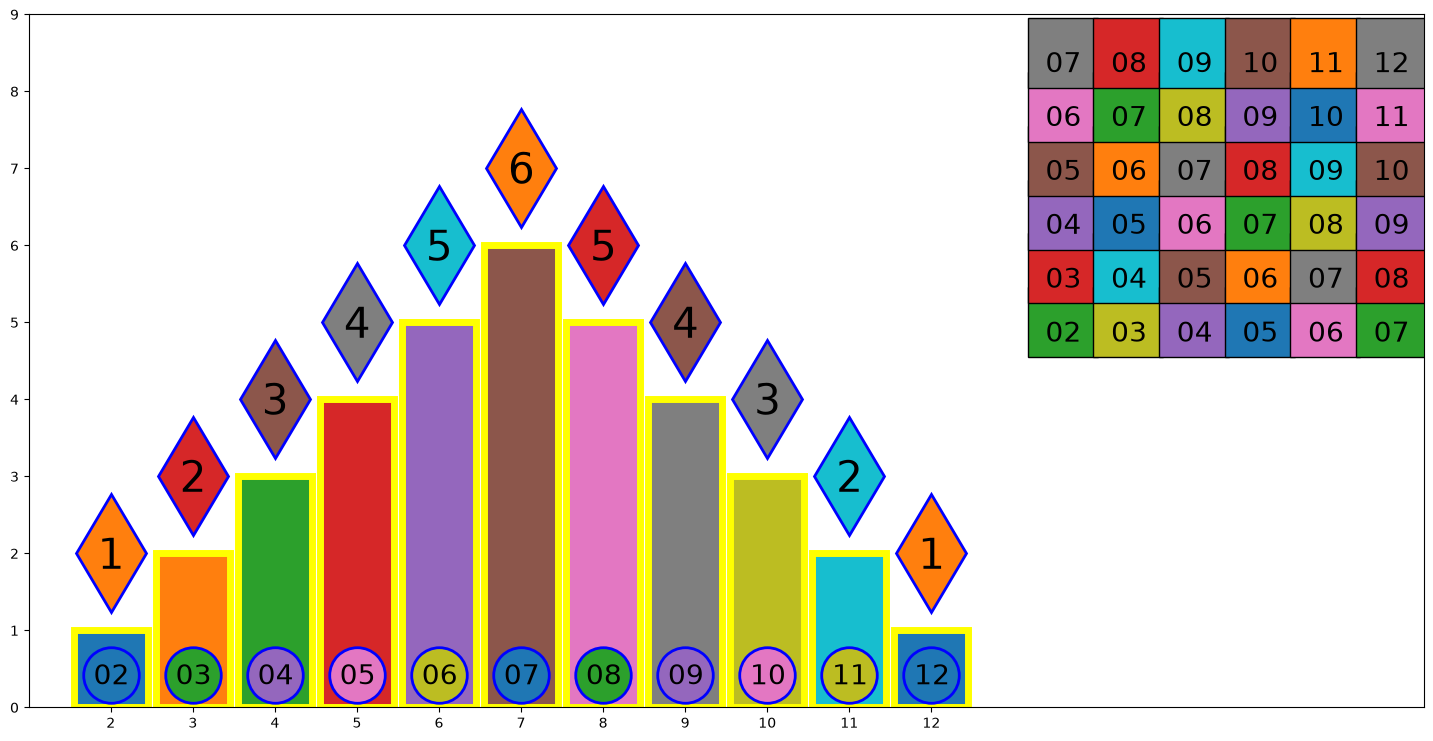

In [320]:
plt.figure(figsize=(18,9))
plt.ylim(0,9)
plt.xlim(1,18)
for key ,val in dictc.items():
    plt.bar(key,val,edgecolor="yellow",width=0.9,lw=5)
    plt.plot(key,0.42,marker="o",ms=40,mec="blue",mew=2)  
    plt.annotate("{}".format(str(int(key)).zfill(2)),xy=(key-0.21,0.3),size=20)
    
    plt.annotate("{}".format(val),xy=(key-0.16,val+0.8),size=30)
    plt.plot(key,val+1,marker="d",ms=60,mec="blue",mew=2)    

x1=np.arange(13.6,13.6+0.8*6,0.8)
y1=np.arange(5,5+0.7*6,0.7)
for i in range(6):
    for j in range(6):
        plt.plot(x1[i],y1[j],"s",ms=50,mec="black")
        plt.annotate( "{}".format(str(int(matrix_q44[i,j])).zfill(2)), xy=(x1[i]-0.21,y1[j]-0.25),size=20)
plt.xticks(np.arange(2,13))
plt.show()